# K-space

**Part:** F – Image formation · **Reading time:** ~60 min · **Pass 1 overview:** [From Signal to Image](../pass1_big_picture/P1.3_From_Signal_to_Image.ipynb) · **Refreshers you may want:** [Continuous FT and DFT](../refreshers/RM3_Continuous_FT_and_DFT.ipynb), [Fourier properties](../refreshers/RM4_Fourier_Properties.ipynb), [Fourier pairs and sampling](../refreshers/RM5_Fourier_Pairs_and_Sampling.ipynb), [2D Fourier and images](../refreshers/RM6_2D_Fourier_and_Images.ipynb), [Complex numbers & rotations](../refreshers/RM2_Complex_Numbers_and_Rotations.ipynb)

**Why this chapter matters.** MRI is a *Fourier imaging* technique: the scanner never measures the image directly, it measures the image's **spatial-frequency content**, one sample at a time. The bookkeeping device that tells us *which* spatial frequency we are measuring at each instant is **k-space**, and the path we steer through it with the gradients is the **k-space trajectory**. Once you can turn gradient waveforms into a k-space trajectory (an integral) and back (a derivative), you can read any pulse sequence diagram, understand FOV, resolution and artifacts, and design fast acquisitions (EPI, spiral, radial).

## Learning goals

1. Describe how images are formed
    * Understand why MRI is a Fourier imaging method — derive the Fourier relation from the signal equation
    * Describe how MRI data are accumulated and sorted
    * Describe what a k-space trajectory is
2. Compute the k-space trajectory $\vec k(t)$ numerically from gradient waveforms (and gradients from a desired trajectory), including prephasers, rewinders and the effect of 180° refocusing pulses
3. Explain what a single point of k-space "means" (a stripe pattern) and which image features the center and the edges of k-space carry
4. Compare Cartesian, echo-planar, radial and spiral trajectories, including their hardware (gradient and slew-rate) demands

## Symbols used in this chapter

| Symbol | Meaning (plain words) | SI unit | Typical value / remark |
|---|---|---|---|
| $\vec r=[x,y,z]^T$ | position | m | |
| $t$, $\tau$ | time; $\tau$ = dummy integration variable | s | $t=0$ at the end (center) of excitation |
| $\vec G(t)=[G_x,G_y,G_z]^T$ | gradient waveform | T/m | ≤ 40–80 mT/m |
| $SR$ | slew rate, max $\lvert dG/dt\rvert$ | T/m/s | 100–200 T/m/s |
| $\gamma$, $\bar\gamma=\gamma/2\pi$ | gyromagnetic ratio (angular / in Hz) | rad s⁻¹ T⁻¹ / Hz/T | ¹H: $2.675\times10^8$ / 42.58 MHz/T |
| $\omega(\vec r,t)$ | local precession angular frequency in the rotating frame | rad/s | |
| $\phi(\vec r,t)$ | accumulated phase of $M_{xy}$ | rad | |
| $M_{xy}(\vec r,t)$ | transverse magnetization (complex, rotating frame) | normalized | |
| $m(\vec r)=M_{xy}(\vec r,0)$ | transverse magnetization right after excitation (the "image") | a.u. | |
| $s(t)$ | received, demodulated signal | V (a.u.) | |
| $\vec k(t)=[k_x,k_y,k_z]^T$ | k-space position = $\bar\gamma\int_0^t\vec G\,d\tau$ | m⁻¹ (cycles/m) | ±100–1000 m⁻¹ |
| $M(\vec k)=\mathcal F\{m\}$ | k-space data (Fourier transform of $m$) — **not** magnetization | a.u. · m² (2D) | |
| $\mathcal F$, $\mathcal F^{-1}$ | (inverse) Fourier transform, kernel $e^{\mp i2\pi\vec k\cdot\vec r}$ | | |
| $A$ | gradient area $\int G\,dt$ | T s/m | e.g. 5 mT/m × 1 ms = 5 µT s/m |
| $\Delta k$, $k_{max}$ | k-space sample spacing; largest sampled $\lvert k \rvert$ | m⁻¹ | $\Delta k=1/FOV$, $k_{max}=1/(2\delta)$ |
| $FOV$, $\delta$ | field of view; pixel size | m | 0.24 m; ~1 mm |
| $N$, $N_{read}$, $N_{PE}$ | matrix size; readout samples; phase-encoding steps | – | 64–512 |
| $G_{x,r}$, $G_{y,PE}$, $G_{yi}$, $t_y$ | readout amplitude; max PE amplitude; PE increment; PE lobe duration | T/m, T/m, T/m, s | see [Spatial Encoding](../pass2_deep_dive/F1_Spatial_Encoding.ipynb) |
| $\Delta t$, $BW_{read}=1/\Delta t$, $T_{read}$ | dwell time; readout bandwidth; readout duration | s, Hz, s | 15.6 µs, 64 kHz, 4 ms |
| $TE$, $TR$ | echo time; repetition time | s | |
| $\theta$, $b_1(t)$ | flip angle; complex RF envelope (rotating frame) | rad, T | 180° refocusing pulse |
| $N_{turns}$, $N_{int}$ | number of spiral turns; number of interleaves | – | |
| $T_2^*$, $\Delta f$ | effective transverse relaxation time; off-resonance | s, Hz | neglected in the ideal signal equation |
| $C(\vec r)$ | receive-coil sensitivity | – | assumed 1 here |

> **⚠️ Common confusion:** $M_{xy}$ (or $\vec M$) = magnetization; $M(\vec k)$ = k-space data. Same letter, different things — Larson's notation, kept here because it is standard in MRI papers. Also, $k$ in this chapter is always a *spatial frequency* in cycles per metre; it is not the Boltzmann constant ($k_B$).

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath(".."))   # make ../mri_tools.py importable
import numpy as np
import matplotlib.pyplot as plt
import mri_tools as mt
mt.setup_plots()
%matplotlib inline

## 1. Generalized spatial encoding

In general, applied magnetic field gradients change the phase of the transverse magnetization depending on the gradient waveforms and on position:

$$ M_{xy}(\vec{r}, t) = M_{xy}(\vec{r}, 0) \exp\left( -i \gamma \int_0^t \vec{G}(\tau) \cdot \vec{r} \ d\tau \right) $$

In words: each spin packet keeps its magnitude but its phase is rotated by an angle equal to $\gamma$ times "how much extra field it has seen, integrated over time".

where $M_{xy}=M_x+iM_y$ is the transverse magnetization in the rotating frame, $\gamma$ [rad s⁻¹ T⁻¹], $\vec G(\tau)$ [T/m] the gradient waveform, $\vec r$ [m] the (fixed) position, and $t=0$ is the end of the excitation.

<details><summary><b>📐 Derivation (optional): from the Bloch equation to this phase factor</b></summary>

1. In the rotating frame (rotating at $f_0$) the only remaining $z$-field is the gradient's: $\Delta B_z(\vec r,t)=\vec G(t)\cdot\vec r$. So each spin packet precesses at the local angular frequency $\omega(\vec r,t)=\gamma\,\vec G(t)\cdot\vec r$.
2. Ignoring relaxation and RF, the transverse part of the Bloch equation ([Bloch Equation](../pass2_deep_dive/A2_Bloch_Equation.ipynb)) for $M_{xy}=M_x+iM_y$ reads $\dfrac{dM_{xy}}{dt} = -i\,\omega(\vec r,t)\,M_{xy}$ (clockwise precession, see [Complex numbers & rotations](../refreshers/RM2_Complex_Numbers_and_Rotations.ipynb)).
3. This is a first-order linear ODE with a time-varying coefficient. Divide by $M_{xy}$: $\frac{d}{dt}\ln M_{xy} = -i\omega(t)$. Integrate from $0$ to $t$: $\ln M_{xy}(t)-\ln M_{xy}(0) = -i\int_0^t\omega(\tau)d\tau$. Exponentiate: $M_{xy}(t)=M_{xy}(0)\,e^{-i\int_0^t\omega(\tau)d\tau}$ (see [ODE refresher](../refreshers/RM1_ODEs_for_MRI.ipynb)).
4. Insert $\omega$: $\int_0^t \gamma\vec G(\tau)\cdot\vec r\,d\tau = \gamma\,\vec r\cdot\int_0^t\vec G(\tau)d\tau$, where we could pull $\vec r$ out of the integral because the spins **do not move** (moving spins give flow/motion effects, see [Artifacts](../pass2_deep_dive/I2_Artifacts.ipynb)).

</details>

Using the notation $m(\vec{r}) = M_{xy}(\vec{r}, t=0)$, this can be written as

$$M_{xy}(\vec{r}, t) = m(\vec{r}) \exp\left( -i \gamma \int_0^t \vec{G}(\tau) \cdot \vec{r} \ d\tau \right)$$

In words: the magnetization at time $t$ is the initial "image" multiplied by a position-dependent phase factor that is entirely determined by the gradient history.

A key fact here is that **the phase accumulation depends on the cumulative gradient area** (the integral of the gradient). This means we can turn the gradients on and off to start and stop the phase accumulation, and also reverse the gradient polarity to undo prior phase accumulation.

Let us check this with a Bloch simulation (`mt.bloch_simulate`, rotating frame, no relaxation): spins along $x$ see a negative gradient lobe and then a positive one of twice the duration. The phase spreads, is undone, and spreads again; the total signal $|s(t)|=|\sum M_{xy}|$ shows a **gradient echo** exactly when the net area returns to zero.

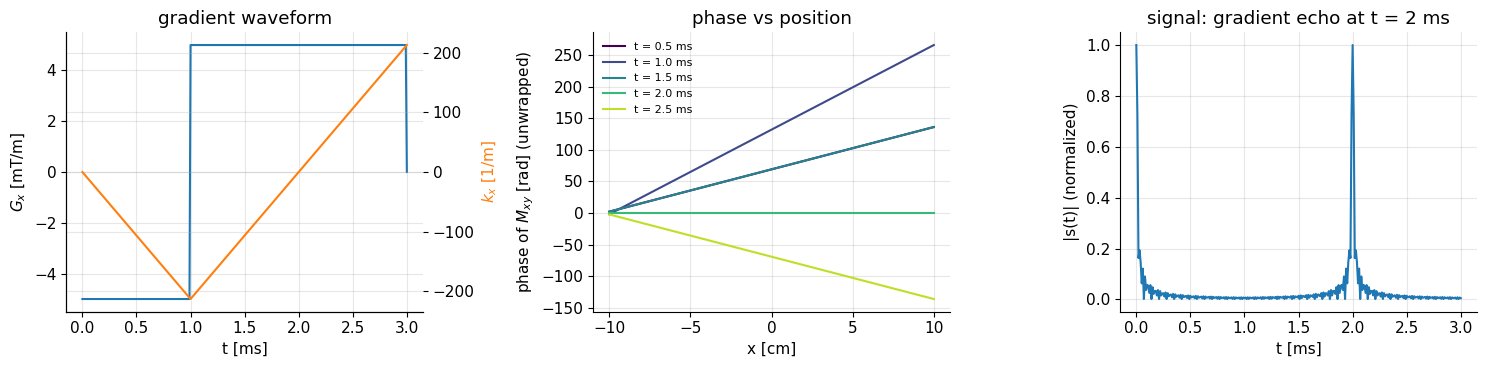

In [2]:
dt = 10e-6                                        # time step [s]
x = np.linspace(-0.1, 0.1, 201)                   # spin positions [m]
r = np.stack([x, 0 * x, 0 * x], axis=-1)
Gamp = 5e-3                                       # 5 mT/m
Gx = np.concatenate([-Gamp * np.ones(100), Gamp * np.ones(200)])   # -1 ms lobe, then +2 ms
G = np.zeros((len(Gx), 3)); G[:, 0] = Gx
t, M = mt.bloch_simulate(G=G, r=r, dt=dt, M_init=(1.0, 0.0, 0.0))  # M_xy = 1 after excitation
Mxy = M[:, :, 0] + 1j * M[:, :, 1]               # (Nt+1, Nspins)
s = Mxy.mean(axis=1)                              # total signal (normalized)
kx = mt.GAMMA_BAR * np.concatenate([[0], np.cumsum(Gx)]) * dt   # k_x(t) [1/m]

fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
ax[0].plot(t * 1e3, np.concatenate([Gx, [0]]) * 1e3); ax[0].set(xlabel="t [ms]", ylabel="$G_x$ [mT/m]",
                                                               title="gradient waveform")
ax0b = ax[0].twinx(); ax0b.plot(t * 1e3, kx, "C1"); ax0b.set_ylabel("$k_x$ [1/m]", color="C1")
for ti, c in zip([0.5e-3, 1.0e-3, 1.5e-3, 2.0e-3, 2.5e-3], plt.cm.viridis(np.linspace(0, 0.9, 5))):
    i = int(round(ti / dt))
    ax[1].plot(x * 100, np.unwrap(np.angle(Mxy[i])), color=c, label=f"t = {ti*1e3:.1f} ms")
ax[1].set(xlabel="x [cm]", ylabel="phase of $M_{xy}$ [rad] (unwrapped)", title="phase vs position")
ax[1].legend(fontsize=8)
ax[2].plot(t * 1e3, np.abs(s)); ax[2].set(xlabel="t [ms]", ylabel="|s(t)| (normalized)",
                                         title="signal: gradient echo at t = 2 ms")
plt.tight_layout(); plt.show()

Interpretation: the phase is always a straight line in $x$ whose slope is $-2\pi k_x(t)$ (orange curve, left): the slope grows during the negative lobe, returns to zero at $t = 2$ ms (where the positive lobe has cancelled the negative area) and then grows with opposite sign. The signal is maximal precisely when the phase is flat — the gradient echo. Only the *running area* matters.

### Definition of k-space

Here we introduce k-space, a compact representation of the phase accumulation due to magnetic field gradients. It is defined as

$$\vec{k}(t) = [k_x(t), k_y(t), k_z(t)]^T = \bar\gamma \int_0^t \vec{G}(\tau) \ d\tau = \frac{\gamma}{2\pi} \int_0^t \vec{G}(\tau) \ d\tau$$

In words: the k-space position is the running gradient area, scaled by $\bar\gamma$. Each component is controlled by its own gradient coil: $k_x$ by $G_x$, etc.

where $\bar\gamma=\gamma/2\pi$ [Hz/T], so the unit is Hz/T · T/m · s = **1/m** (cycles per metre). Example: 10 mT/m for 1 ms gives $k = 42.58\times10^6\cdot 10^{-2}\cdot10^{-3} \approx 426$ m⁻¹, i.e. a phase pattern that repeats every $1/k\approx 2.35$ mm.

The effect of gradients on the transverse magnetization then becomes

$$M_{xy}(\vec{r}, t) =  m(\vec{r})\, e^{ -i 2 \pi \vec{k}(t) \cdot \vec{r} }$$

In words: at every moment the initial image is multiplied by a **plane-wave "stripe" pattern** whose stripes are perpendicular to $\vec k$ and repeat $|\vec k|$ times per metre.

(Check: $2\pi\,\vec k\cdot\vec r = 2\pi\bar\gamma\,\vec r\cdot\int\vec G = \gamma\int\vec G\cdot\vec r$ ✓.) The motivation for k-space becomes clear when we write the signal equation and find a Fourier transform.

## 2. The MRI signal in the Fourier domain

The MRI signal comes from the precession of the transverse magnetization, and is proportional to it. It comes from *all* precessing magnetization within the sensitive volume of the receive coil, i.e. it is summed over the volume (we take the coil sensitivity $C(\vec r)=1$ and drop constant factors; the complete version with $C(\vec r)$, relaxation and off-resonance is in [MRI Signal Equation](../pass2_deep_dive/C2_MRI_Signal_Equation.ipynb)):

$$\begin{aligned}
s(t) & = \int M_{xy}(\vec{r},t) \ d\vec{r} \\
 & =  \int m(\vec{r}) \exp(-i2\pi \vec{k}(t) \cdot \vec{r}) \ d\vec{r}
 \end{aligned}$$

In words: the signal at time $t$ is the sum over the object of (image) × (stripe pattern of the current $\vec k$). In 2D, written out: $s(t)=\iint m(x,y)\,e^{-i2\pi(k_x(t)x+k_y(t)y)}\,dx\,dy$.

where $d\vec r = dx\,dy\,dz$ and the integral runs over the whole object.

The amazing result is that this describes the MRI signal as a **Fourier transform**. The (continuous, multidimensional) Fourier transform is

$$\mathcal{F} \{ f(\vec{r}) \} = F(\vec{k}) = \int_{-\infty}^\infty f(\vec{r}) \exp(-i 2 \pi \vec{k} \cdot  \vec{r}) \ d\vec{r}$$

In words: $F(\vec k)$ measures "how much of the plane wave with spatial frequency $\vec k$ is contained in $f$".

where $\vec k$ is a free variable (spatial frequency, 1/m). Unlike the DFT you know, it uses an integral over continuous position and is defined for every real $\vec k$; the DFT is its sampled, finite version ([Continuous FT and DFT](../refreshers/RM3_Continuous_FT_and_DFT.ipynb)). The 2D FT is just a 1D FT along $x$ followed by one along $y$ (separability, [2D Fourier and images](../refreshers/RM6_2D_Fourier_and_Images.ipynb)).

Comparing the two equations: our signal is the Fourier transform of the initial transverse magnetization, evaluated at the spatial frequency $\vec k$ given by the trajectory $\vec k(t)$:

$$ s(t) = \mathcal{F} \{ M_{xy}(\vec{r},0) \} \big|_{\vec{k} = \vec{k}(t)} $$

Defining the k-space data

$$\mathcal{F}\{ m(\vec{r}) \} = M(\vec{k})$$

we get the key result

$$ s(t) = M(\vec{k}(t)) $$

In words: **the received signal is the Fourier transform of the transverse magnetization, evaluated at the k-space location determined by the gradients.** MRI signals are measurements of the spatial frequencies of the object. To reconstruct an image, we put each signal sample at its k-space location and apply an inverse Fourier transform.

> **⚠️ Common confusion:** time and k are linked only through the gradients. The signal is *recorded* as a function of time, but it *means* something as a function of k. Two samples at very different times (e.g. in different TRs) can be neighbours in k-space.

> **🔧 Engineering reality:** the ideal relation $s(t)=M(\vec k(t))$ assumes (1) the actual gradients equal the requested ones (in reality: amplifier delays, eddy currents, gradient non-linearity — [Gradient System Engineering](../pass2_deep_dive/B4_Gradient_System_Engineering.ipynb)), (2) no relaxation during the readout (in reality $T_2^*$ decay weights k-space — [Point Spread Function Analysis](../pass2_deep_dive/I1_Point_Spread_Function_Analysis.ipynb)), (3) no off-resonance $\Delta f$ (otherwise phase $-2\pi\Delta f\,t$ adds and shifts/blurs the image — [Artifacts](../pass2_deep_dive/I2_Artifacts.ipynb)). Violations of each are a major source of artifacts, especially for fast non-Cartesian trajectories.

## 3. What does one point of k-space "mean"?

From $s(t) = \int m(\vec r)e^{-i2\pi\vec k\cdot\vec r}d\vec r$, one k-space sample is the **inner product of the object with one complex stripe pattern** (a 2D plane wave):

* the stripes are perpendicular to the direction of $\vec k$,
* their spacing (wavelength) is $1/|\vec k|$,
* $\vec k = 0$ is the "pattern" that is 1 everywhere: $M(0)=\int m\,d\vec r$ is the total signal.

Conversely, the inverse FT $m(\vec r)=\int M(\vec k)e^{+i2\pi\vec k\cdot\vec r}d\vec k$ says the image is a **weighted sum of stripe patterns**, with the k-space data as weights. (Refresher with many pictures: [2D Fourier and images](../refreshers/RM6_2D_Fourier_and_Images.ipynb).)

Below we use a real brain image (the magnitude of the sagittal T1 dataset reconstructed in [Image Reconstruction](../pass2_deep_dive/F3_Image_Reconstruction.ipynb)) as the object $m$, and for a few $\vec k$ we show the stripe pattern and the value of $M(\vec k)$ computed in two ways: directly as the sum $\sum m\,e^{-i2\pi\vec k\cdot\vec r}\,\delta^2$ ("what the scanner measures") and from the FFT of the image ("what the computer does"). They agree.

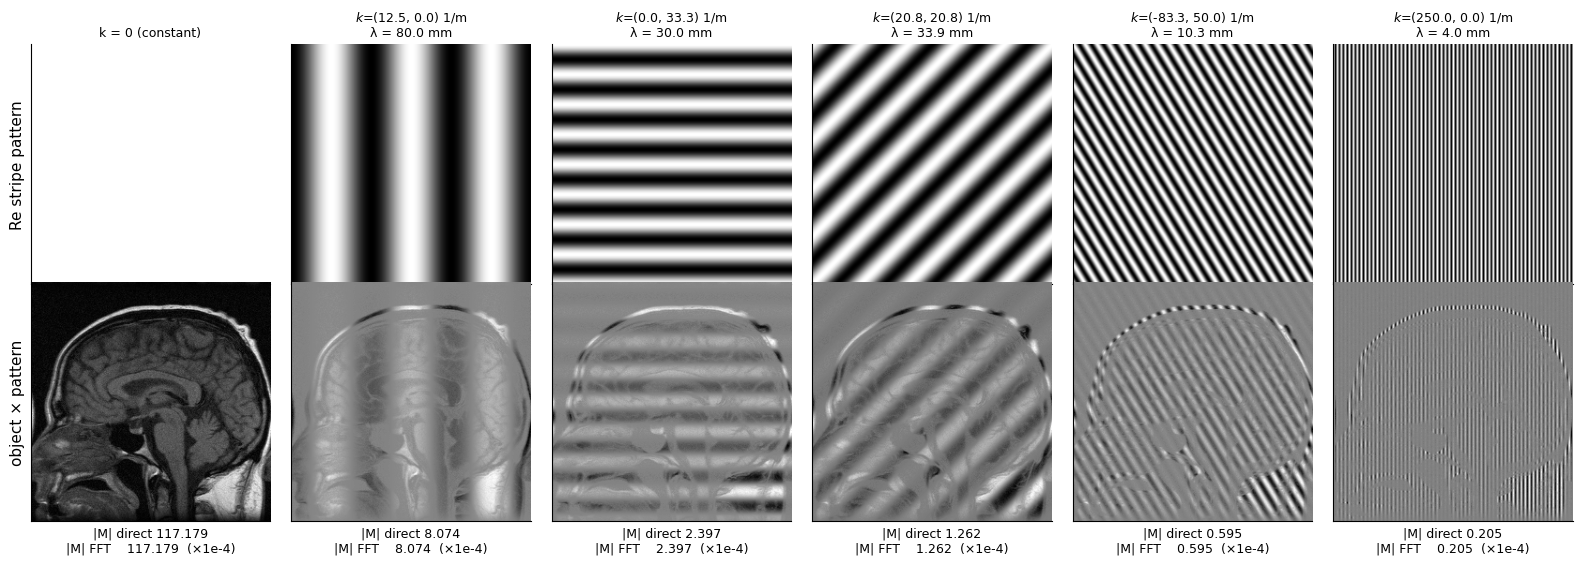

In [3]:
from scipy.io import loadmat
raw = loadmat("../data/se_t1_sag_data.mat")["data"]       # 256 x 256 k-space (see F3)
img = np.abs(mt.ifft2c(raw)); img = img / img.max()        # use the magnitude as our "object" m(x,y)
N = img.shape[0]
FOV = 0.24                                                  # assume a 24 cm FOV [m]
dpix = FOV / N                                              # pixel size [m]
pos = (np.arange(N) - N // 2) * dpix                        # pixel positions [m]
X, Y = np.meshgrid(pos, pos)                                # x along columns, y along rows
Kimg = mt.fft2c(img) * N * dpix**2       # FFT -> continuous-FT samples M(k) at k = (index - N/2)/FOV
                                         # (ortho fft2c = fft2 / N, so multiply by N, and by the pixel area)

cases = [(0, 0), (3, 0), (0, 8), (5, 5), (-20, 12), (60, 0)]   # (cycles across FOV in x, in y)
fig, axs = plt.subplots(2, len(cases), figsize=(16, 5.6))
for j, (cx, cy) in enumerate(cases):
    kxv, kyv = cx / FOV, cy / FOV                                 # [1/m]
    pattern = np.exp(-1j * 2 * np.pi * (kxv * X + kyv * Y))
    M_direct = np.sum(img * pattern) * dpix**2                    # the "measurement" [a.u. m^2]
    M_fft = Kimg[N // 2 + cy, N // 2 + cx]                        # row = k_y index, column = k_x index
    axs[0, j].imshow(pattern.real, cmap="gray", vmin=-1, vmax=1); axs[0, j].grid(False)
    axs[0, j].set_title(f"$k$=({kxv:.1f}, {kyv:.1f}) 1/m\nλ = {1e3/max(np.hypot(kxv,kyv),1e-9):.1f} mm"
                        if (cx, cy) != (0, 0) else "k = 0 (constant)", fontsize=9)
    axs[1, j].imshow(img * pattern.real, cmap="gray"); axs[1, j].grid(False)
    for a in axs[:, j]: a.set_xticks([]); a.set_yticks([])
    axs[1, j].set_xlabel(f"|M| direct {abs(M_direct)*1e4:.3f}\n|M| FFT    {abs(M_fft)*1e4:.3f}  (×1e-4)",
                         fontsize=9)
axs[0, 0].set_ylabel("Re stripe pattern"); axs[1, 0].set_ylabel("object × pattern")
plt.tight_layout(); plt.show()

Interpretation: each k-space value is literally "object times stripes, summed up". Low $|\vec k|$ (coarse stripes) overlaps strongly with the large-scale brightness distribution, so $|M|$ is large; fine stripes (60 cycles across 24 cm, λ = 4 mm) mostly average out, so $|M|$ is small — but these small values carry the edges and fine detail.

### Center vs. edges of k-space

Let us reconstruct the image using only the central part of k-space, and using everything *except* the center.

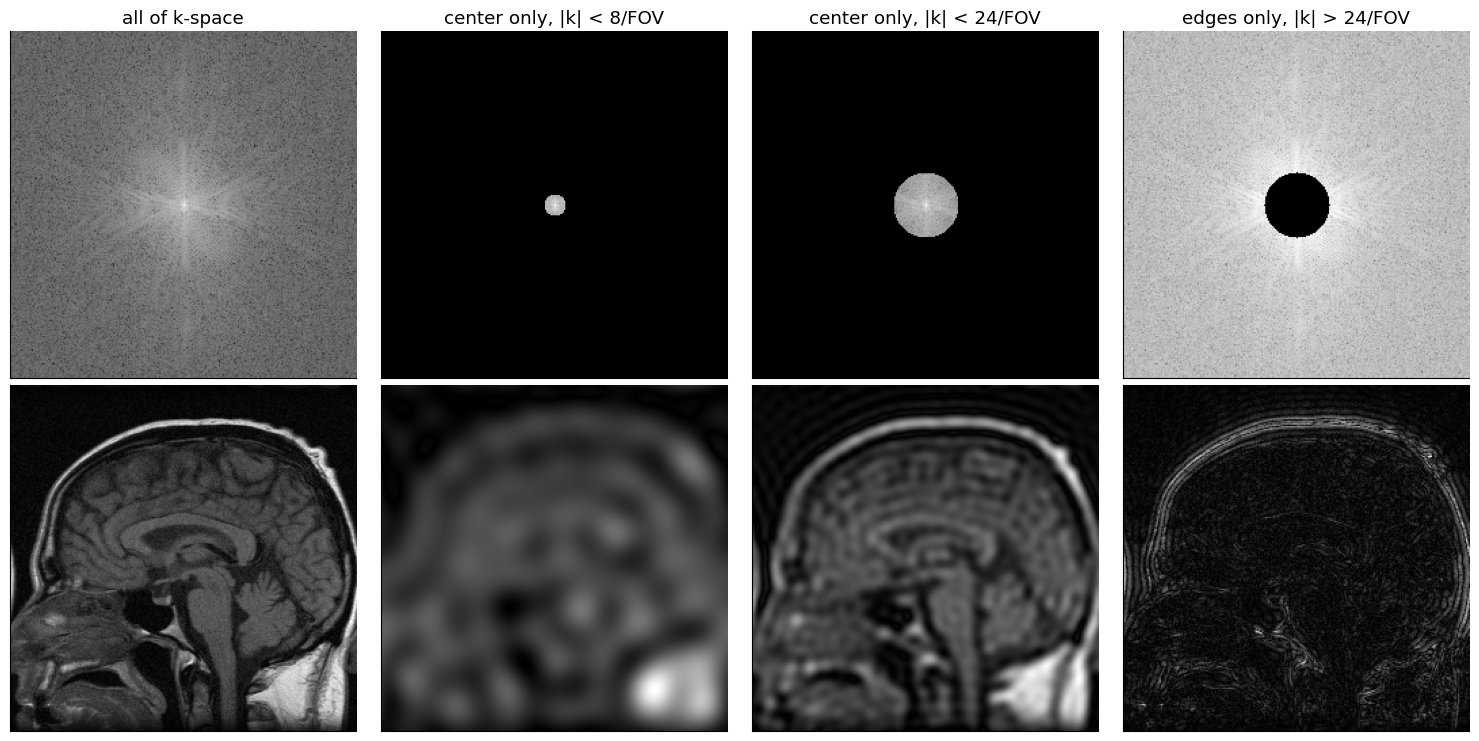

fraction of total signal energy in |k| < 24/FOV: 0.934  (only 2.7% of the samples)


In [4]:
K = mt.fft2c(img)
ky_idx, kx_idx = np.meshgrid(np.arange(N) - N // 2, np.arange(N) - N // 2, indexing="ij")
kr = np.hypot(kx_idx, ky_idx)                       # |k| in units of 1/FOV
fig, axs = plt.subplots(2, 4, figsize=(15, 7.5))
masks = [("all of k-space", kr >= 0), ("center only, |k| < 8/FOV", kr < 8),
         ("center only, |k| < 24/FOV", kr < 24), ("edges only, |k| > 24/FOV", kr > 24)]
for j, (name, msk) in enumerate(masks):
    mt.show_kspace(K * msk + 1e-12, ax=axs[0, j], title=name)
    mt.show_image(mt.ifft2c(K * msk), ax=axs[1, j])
plt.tight_layout(); plt.show()
print(f"fraction of total signal energy in |k| < 24/FOV: {np.sum(np.abs(K[kr<24])**2)/np.sum(np.abs(K)**2):.3f}"
      f"  (only {np.mean(kr<24)*100:.1f}% of the samples)")

Interpretation: the **center** of k-space (a few % of the samples) holds almost all the signal energy and determines the overall brightness and **contrast** (which is why the time at which the center is acquired defines the effective TE, and why "center-out" orderings matter for contrast preparation). The **edges** hold the **fine detail and edges** — on their own they look like an edge-detected image. The extent of k-space covered therefore sets the resolution, $\delta = 1/(2k_{max})$, and the spacing sets the FOV, $FOV=1/\Delta k$ ([FOV and Resolution](../pass2_deep_dive/G1_FOV_and_Resolution.ipynb)).

### The image as a sum of stripe patterns

To make "the image is a weighted sum of stripe patterns" tangible, we add up the patterns one by one, ordered from the lowest to the highest $|\vec k|$, and show the partial sums.

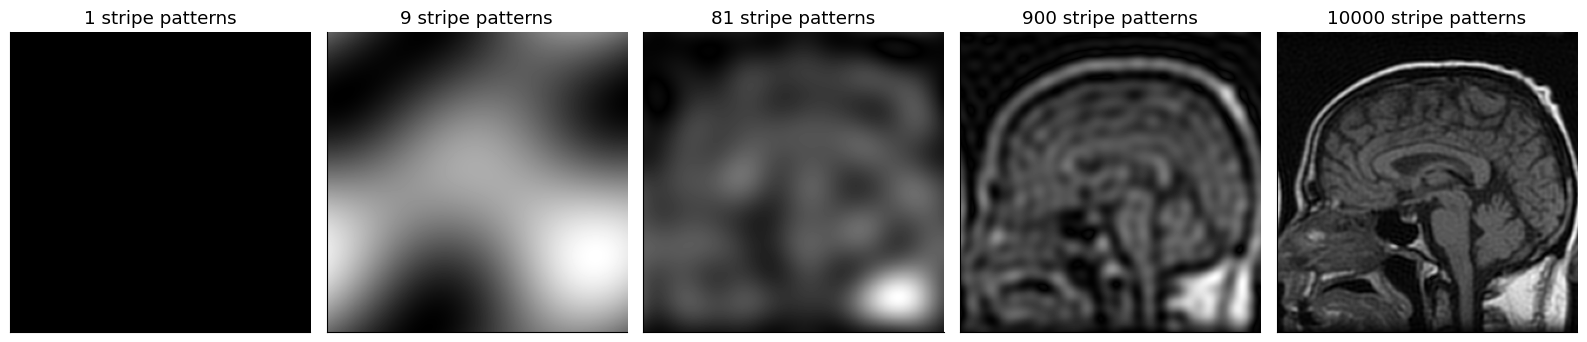

In [5]:
order = np.argsort(kr.ravel())                       # k-space indices from center outwards
fig, axs = plt.subplots(1, 5, figsize=(16, 3.6))
for a, n_terms in zip(axs, [1, 9, 81, 900, 10000]):
    Kp = np.zeros(N * N, complex); Kp[order[:n_terms]] = K.ravel()[order[:n_terms]]
    mt.show_image(mt.ifft2c(Kp.reshape(N, N)), ax=a, title=f"{n_terms} stripe patterns")
plt.tight_layout(); plt.show()

Interpretation: one pattern ($\vec k=0$) gives a uniform gray; tens of patterns give a blurry blob in the right place; a few thousand (of 65 536) already give a recognizable brain. This is also the idea behind **image compression** and **compressed sensing** ([Accelerated Imaging Methods](../pass2_deep_dive/H3_Accelerated_Imaging_Methods.ipynb)).

## 4. From MRI data to images

The flow of the experiment and the data is:

1. RF excitation creates transverse magnetization, $M_{xy}(\vec{r},0)=m(\vec r)$.
2. Gradients $\vec{G}(t)$ are applied and data are acquired.
3. The k-space locations $\vec{k}(t)=\bar\gamma\int_0^t\vec G\,d\tau$ are determined from the applied gradients.
4. Each signal sample is the Fourier transform of the transverse magnetization at that k-space location: $s(t) = M(\vec{k}(t))$.
5. The signal samples (from all TRs) are stored in a data matrix at their known k-space locations, building up $M(\vec{k})$.
6. An inverse Fourier transform reconstructs an image of the transverse magnetization: $\mathcal{F}^{-1}\{ M(\vec{k} )\} = m(\vec{r})$ ([Image Reconstruction](../pass2_deep_dive/F3_Image_Reconstruction.ipynb)).

***Key result:*** *we have now the incredible result that we used magnetic field gradients, the k-space framework, and appropriate acquisition and ordering of the MR signal to create an* **IMAGE**!

## 5. K-space trajectories

K-space is a very general way to capture the effect of spatial-encoding gradients, and the **k-space trajectory** is the path traced over time by

$$\vec{k}(t) = \bar\gamma \int_0^t \vec{G}(\tau)\, d\tau$$

In words: start at the origin and move in the direction of the current gradient vector, with a speed $|d\vec k/dt| = \bar\gamma|\vec G|$ proportional to the gradient strength.

Note that k-space trajectories always **start at the center**, $\vec{k}(0) = 0$, and are only defined once there is transverse magnetization (i.e. after an RF excitation pulse; each new excitation restarts at $\vec k=0$, and refocusing pulses modify it, see below).

The following simulation of the magnetizations shows the rotations and the k-space trajectory during a typical Cartesian (2DFT) gradient-echo sequence. It differs from the simulation in [Spatial Encoding](../pass2_deep_dive/F1_Spatial_Encoding.ipynb) in that an initial **dephasing (prephaser) gradient** in the frequency-encoding direction is applied, so that both positive and negative spatial frequencies are sampled:

![Cartesian trajectory with prephaser: M_xy arrows, gradients and k-space trajectory](../images/frequency_phase_encoding-full-Mxy.gif)

![Cartesian trajectory with prephaser: phase map of M_xy, gradients and k-space trajectory](../images/frequency_phase_encoding-full-image_phase.gif)

(The original generates these movies with `spatial_encoding_Mxy_illustration.m`; [Spatial Encoding](../pass2_deep_dive/F1_Spatial_Encoding.ipynb) contains a Python port.)

### Mapping gradients to the k-space trajectory

To find the trajectory, compute the integral (numerically: the cumulative sum) of the gradients after excitation:

$$\vec k(t_j) \approx \bar\gamma \sum_{l \le j} \vec G(t_l)\,\Delta\tau$$

In words: add up gradient × time step, scaled by $\bar\gamma$.

where $\Delta\tau$ [s] is the simulation time step. Once $\vec k(t)$ is known, we can plot it to see the k-space coverage of the chosen gradients. Conversely, to find the gradients for a desired trajectory, differentiate:

$$\vec G(t) = \frac{1}{\bar\gamma}\frac{d\vec k}{dt}$$

In words: the gradient is the "velocity" in k-space (divided by $\bar\gamma$), and the **slew rate** $d\vec G/dt = \frac{1}{\bar\gamma}\frac{d^2\vec k}{dt^2}$ is its "acceleration". Hardware limits on $|G|$ and $|dG/dt|$ are limits on the speed and acceleration through k-space.

First, the Python code of the original (normalized units: time in arbitrary units, $\bar\gamma$ absorbed so that $k$ = cumulative sum of $G$, $k$ in cycles/pixel). We wrap it in a function so that you can pick the phase-encoding line `i_pe`.

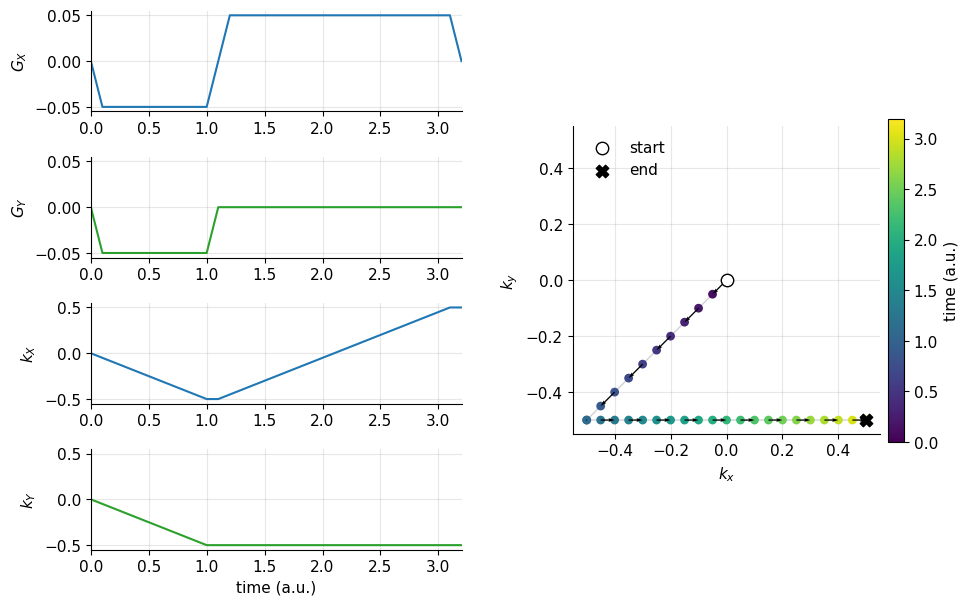

In [6]:
import matplotlib.gridspec as gridspec

def original_trajectory_demo(i_pe=0, N_PE=8, dt=0.1, Tpe=1.0, Tfe=2.0, kFE=0.5):
    """Port of the original notebook's cell (normalized units)."""
    kPE = np.linspace(-N_PE / 2, N_PE / 2, N_PE + 1) / N_PE       # phase-encoding k values
    Tall = np.arange(0, Tpe + Tfe + 2 * dt + dt / 2, dt)
    n_tpe, n_tfe = int(round(Tpe / dt)), int(round(Tfe / dt))
    GY = np.zeros_like(Tall); GX = np.zeros_like(Tall)
    GY[1:n_tpe + 1] = kPE[i_pe] / (Tpe / dt)        # phase-encoding lobe
    GX[1:n_tpe + 1] = -kFE / (Tpe / dt)             # prephaser (negative!)
    GX[n_tpe + 2:len(Tall) - 1] = 2 * kFE / (Tfe / dt)   # readout
    kX, kY = np.cumsum(GX), np.cumsum(GY)           # k = running sum of G

    fig = plt.figure(figsize=(11, 7))
    gs = gridspec.GridSpec(4, 2, width_ratios=[1, 1], wspace=0.3, hspace=0.45)
    for row, (sig, lab, col, lim) in enumerate([(GX, "$G_X$", "C0", .055), (GY, "$G_Y$", "C2", .055),
                                                 (kX, "$k_X$", "C0", .55), (kY, "$k_Y$", "C2", .55)]):
        a = fig.add_subplot(gs[row, 0]); a.plot(Tall, sig, color=col); a.set_ylabel(lab)
        a.set_xlim(0, Tall[-1]); a.set_ylim(-lim, lim)
    a.set_xlabel("time (a.u.)")
    ax = fig.add_subplot(gs[:, 1])
    ax.plot(kX, kY, color="lightgray", lw=1)
    sc = ax.scatter(kX, kY, c=Tall, cmap="viridis", s=40, edgecolors="none", zorder=3)
    step = max(1, len(kX) // 12); idx = np.arange(0, len(kX) - 1, step)
    ax.quiver(kX[idx], kY[idx], kX[idx + 1] - kX[idx], kY[idx + 1] - kY[idx], angles="xy",
              scale_units="xy", scale=1, width=0.004, color="k", zorder=4)
    ax.scatter(kX[0], kY[0], marker="o", facecolor="white", edgecolor="black", s=80, zorder=5, label="start")
    ax.scatter(kX[-1], kY[-1], marker="X", color="black", s=80, zorder=5, label="end")
    ax.legend(loc="upper left"); ax.set(xlabel="$k_x$", ylabel="$k_y$", xlim=(-.55, .55), ylim=(-.55, .55))
    ax.set_aspect("equal", adjustable="box")
    fig.colorbar(sc, ax=ax, label="time (a.u.)", shrink=0.6, pad=0.02)
    plt.show()

original_trajectory_demo(i_pe=0)      # change i_pe (0..8) to view other phase-encoding lines

Interpretation: during the first lobe, $G_X<0$ and $G_Y<0$ drive k diagonally from the origin to the lower-left corner $(-\tfrac12,-\tfrac12)$; the readout gradient then sweeps $k_x$ from $-\tfrac12$ to $+\tfrac12$ along one horizontal line. Other `i_pe` values give other lines.

### A realistic gradient-echo sequence in SI units

Now the same with real numbers (the design example of Parts F/G: FOV = 240 mm, $N_{read} = N_{PE} = 256$, $BW_{read} = 64$ kHz, slew rate 150 T/m/s) and trapezoidal gradients. The prephaser area is chosen so that $k_x = -k_{max} = -\tfrac{N}{2}\Delta k$ at the first ADC sample, and the phase-encoding area of step $n$ gives $k_y = (n-1-\tfrac{N}{2})\Delta k$.

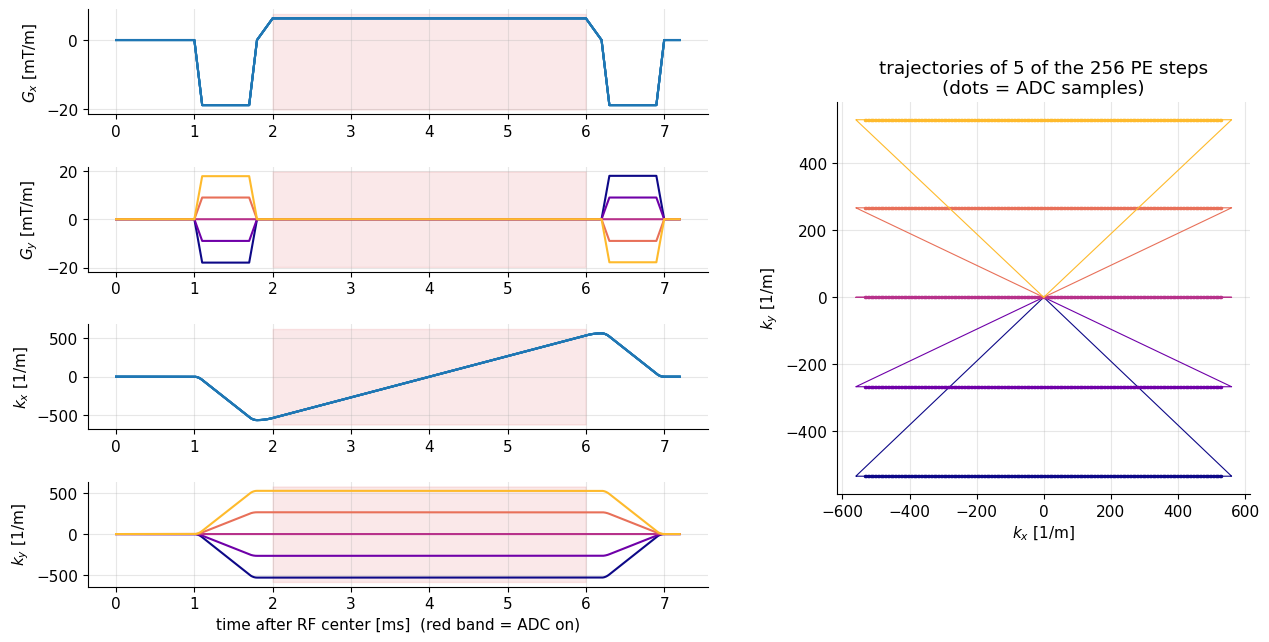

k_x at first ADC sample = -533.1 1/m  (expected -N/2*dk = -533.3)
k_x at the middle of the ADC (echo, TE) = 0.27 1/m
k_x after the rewinder = -0.00 1/m


In [7]:
def trapezoid(t, t_start, flat, ramp, amp):
    """Trapezoidal gradient [T/m] on time axis t [s]: ramp up, flat top, ramp down."""
    g = np.zeros_like(t)
    t1, t2, t3 = t_start + ramp, t_start + ramp + flat, t_start + 2 * ramp + flat
    up = (t >= t_start) & (t < t1); g[up] = amp * (t[up] - t_start) / ramp
    g[(t >= t1) & (t < t2)] = amp
    dn = (t >= t2) & (t < t3); g[dn] = amp * (t3 - t[dn]) / ramp
    return g

def gre_waveforms(n_pe, N=256, FOV=0.24, BW=64e3, dt=2e-6, SR=150.0, t_lobe=0.6e-3, rewind=True):
    """Gx, Gy, ADC mask and time axis for phase-encoding step n_pe (1..N) of a 2D GRE readout.
    Time t = 0 is the center of the excitation pulse."""
    dk = 1 / FOV
    T_read = N / BW                                      # readout duration [s]
    G_xr = BW / (mt.GAMMA_BAR * FOV)                     # readout amplitude [T/m]
    ramp_r = 0.2e-3                                      # readout ramp time [s]
    ramp_l = 0.1e-3                                      # ramp of the short lobes [s]
    t = np.arange(0, 1.0e-3 + 0.8e-3 + T_read + 2 * ramp_r + 1.0e-3, dt)
    t0 = 1.0e-3                                          # lobes start 1 ms after the RF center
    A_pre = -G_xr * (T_read / 2 + ramp_r / 2)            # prephaser area: brings k_x to -k_max at ADC start
    Gx = trapezoid(t, t0, t_lobe, ramp_l, A_pre / (t_lobe + ramp_l))
    A_pe = (n_pe - 1 - N / 2) * dk / mt.GAMMA_BAR        # phase-encoding area of step n_pe [T s/m]
    Gy = trapezoid(t, t0, t_lobe, ramp_l, A_pe / (t_lobe + ramp_l))
    t_ro = t0 + t_lobe + 2 * ramp_l                      # readout starts after the lobes
    Gx += trapezoid(t, t_ro, T_read, ramp_r, G_xr)
    adc = (t >= t_ro + ramp_r) & (t < t_ro + ramp_r + T_read)
    if rewind:                                           # rewinders: undo the remaining area after the readout
        t_rw = t_ro + T_read + 2 * ramp_r
        Gx += trapezoid(t, t_rw, t_lobe, ramp_l, A_pre / (t_lobe + ramp_l))
        Gy += trapezoid(t, t_rw, t_lobe, ramp_l, -A_pe / (t_lobe + ramp_l))
    return t, Gx, Gy, adc

def k_from_gradients(G, dt):
    """k(t) = gamma_bar * cumulative integral of G [1/m] (rectangle rule)."""
    return mt.GAMMA_BAR * np.cumsum(G) * dt

fig = plt.figure(figsize=(15, 7.5))
gs = gridspec.GridSpec(4, 2, width_ratios=[1.5, 1], wspace=0.25, hspace=0.5)
axG = [fig.add_subplot(gs[i, 0]) for i in range(4)]
axk = fig.add_subplot(gs[:, 1])
for n_pe, col in zip([1, 65, 129, 193, 256], plt.cm.plasma(np.linspace(0, 0.85, 5))):
    t, Gx, Gy, adc = gre_waveforms(n_pe)
    dtw = t[1] - t[0]
    kx, ky = k_from_gradients(Gx, dtw), k_from_gradients(Gy, dtw)
    axG[0].plot(t * 1e3, Gx * 1e3, color="C0"); axG[1].plot(t * 1e3, Gy * 1e3, color=col)
    axG[2].plot(t * 1e3, kx, color="C0"); axG[3].plot(t * 1e3, ky, color=col)
    axk.plot(kx, ky, color=col, lw=0.8)
    axk.plot(kx[adc][::8], ky[adc][::8], ".", color=col, ms=3)      # every 8th ADC sample
for a, lab in zip(axG, ["$G_x$ [mT/m]", "$G_y$ [mT/m]", "$k_x$ [1/m]", "$k_y$ [1/m]"]):
    a.set_ylabel(lab); a.fill_between(t * 1e3, *a.get_ylim(), where=adc, color="C3", alpha=0.1)
axG[3].set_xlabel("time after RF center [ms]  (red band = ADC on)")
axk.set(xlabel="$k_x$ [1/m]", ylabel="$k_y$ [1/m]", title="trajectories of 5 of the 256 PE steps\n(dots = ADC samples)")
axk.set_aspect("equal")
plt.show()

t, Gx, Gy, adc = gre_waveforms(129)
kx = k_from_gradients(Gx, t[1] - t[0])
kx_adc = kx[adc]
dk_expected = 1 / 0.24
print(f"k_x at first ADC sample = {kx_adc[0]:.1f} 1/m  (expected -N/2*dk = {-128*dk_expected:.1f})")
print(f"k_x at the middle of the ADC (echo, TE) = {kx_adc[len(kx_adc)//2]:.2f} 1/m")
print(f"k_x after the rewinder = {kx[-1]:.2f} 1/m")

Interpretation: the **prephaser** (negative $G_x$ lobe) drives $k_x$ *negative*, to $-k_{max}\approx-533$ m⁻¹, while the phase-encoding lobe moves $k_y$ to the line of this repetition. During the ADC, the readout gradient sweeps $k_x$ linearly through zero — the **gradient echo**, which defines $TE$ — up to $+k_{max}$. The **rewinders** at the end bring $k$ back to the origin (needed e.g. for balanced SSFP, [Fast Imaging Pulse Sequences](../pass2_deep_dive/H2_Fast_Imaging_Pulse_Sequences.ipynb)). (The tiny residual errors come from the rectangle-rule integration on a 2 µs grid.)

### Gradient area = k-space displacement

Because $\vec k$ is the running integral, any gradient lobe moves k-space by

$$ \Delta \vec k = \bar\gamma \int_{\text{lobe}} \vec G(\tau)\, d\tau = \bar\gamma\, \vec A $$

In words: the displacement in k-space equals $\bar\gamma$ times the lobe's area; the shape (rectangle, trapezoid, triangle) does not matter.

where $\vec A$ [T s/m] is the area of the lobe on each axis. Useful numbers:

In [8]:
lobes = {  # name: (amplitude [T/m], flat-top duration [s], ramp duration [s])
    "rect 10 mT/m x 1 ms":                 (10e-3, 1e-3, 0),
    "trapezoid 20 mT/m, 0.4 ms + 2x0.13 ms ramps": (20e-3, 0.4e-3, 0.133e-3),
    "triangle 30 mT/m, 2x0.2 ms ramps":    (30e-3, 0.0, 0.2e-3),
    "readout 6.26 mT/m x 4 ms":            (6.26e-3, 4e-3, 0),
}
print(f"{'lobe':48s} {'area [uT s/m]':>14s} {'Delta k [1/m]':>14s} {'cycles over 24 cm':>18s}")
for name, (g, flat, ramp) in lobes.items():
    A = g * (flat + ramp)              # trapezoid area = amp * (flat + ramp)  (two half-ramps)
    dk = mt.GAMMA_BAR * A
    print(f"{name:48s} {A*1e6:14.2f} {dk:14.1f} {dk*0.24:18.1f}")

lobe                                              area [uT s/m]  Delta k [1/m]  cycles over 24 cm
rect 10 mT/m x 1 ms                                       10.00          425.8              102.2
trapezoid 20 mT/m, 0.4 ms + 2x0.13 ms ramps               10.66          453.9              108.9
triangle 30 mT/m, 2x0.2 ms ramps                           6.00          255.5               61.3
readout 6.26 mT/m x 4 ms                                  25.04         1066.1              255.9


Interpretation: a typical readout lobe (6.26 mT/m × 4 ms) covers ≈ 1066 m⁻¹ = $2k_{max}$, i.e. 256 cycles across the 24 cm FOV — exactly what 256 pixels need. Short, strong lobes (prephasers, phase encoding, spoilers) move a similar distance in a fraction of the time.

### Refocusing: rewinders, spoilers and the spin-echo effect on k-space

* A **rewinder** is a lobe with the negative area of everything before it: it returns $\vec k$ to 0 (phase coherence restored).
* A **spoiler** (crusher) does the opposite: it moves $\vec k$ far out (many cycles of phase per voxel), so that leftover transverse magnetization averages to zero within each voxel.
* A **180° refocusing pulse** inverts the phase of the transverse magnetization. This is essential for forming a spin echo ([Gradient and Spin Echoes](../pass2_deep_dive/D3_Gradient_and_Spin_Echoes.ipynb)). Since k-space is encoded in that phase, it also inverts the location in k-space.

If the k-space location just before the 180° pulse (at time $t_{180}$) is $\vec{k}^-(t_{180})$, then just after the pulse it is

$$\vec{k}^+(t_{180}) = -\vec{k}^-(t_{180})$$

In words: a 180° pulse reflects the k-space position through the origin.

<details><summary><b>📐 Derivation (optional)</b></summary>

A 180° rotation about the $x$-axis maps $(M_x, M_y) \to (M_x, -M_y)$, i.e. $M_{xy}\to M_{xy}^*$ (complex conjugate). Before the pulse $M_{xy} = m\,e^{-i2\pi\vec k^-\cdot\vec r}$; after it, $M_{xy} = m^*\,e^{+i2\pi\vec k^-\cdot\vec r} = m^*\,e^{-i2\pi(-\vec k^-)\cdot\vec r}$. So the encoding now corresponds to $\vec k^+=-\vec k^-$ (and the image is conjugated, which only flips its phase — irrelevant for magnitude images, and also undone by the 180° pulse's effect on off-resonance phase: that is the spin echo). For a 180° about $y$ one gets $M_{xy}\to -M_{xy}^*$: same k-space reflection, an extra sign.

</details>

This is why in a **spin-echo** sequence the readout prephaser has the *same* polarity as the readout gradient: the prephaser moves $k_x$ to $+k_{max}$, the 180° pulse flips it to $-k_{max}$, and the readout sweeps it back through 0 at the spin echo.

We verify this with a Bloch simulation that includes an actual (hard) 180° RF pulse: we estimate the "local wavenumber" of the simulated $M_{xy}$ (from the phase difference of neighbouring spins) and compare it with the k-space formula including the reflection.

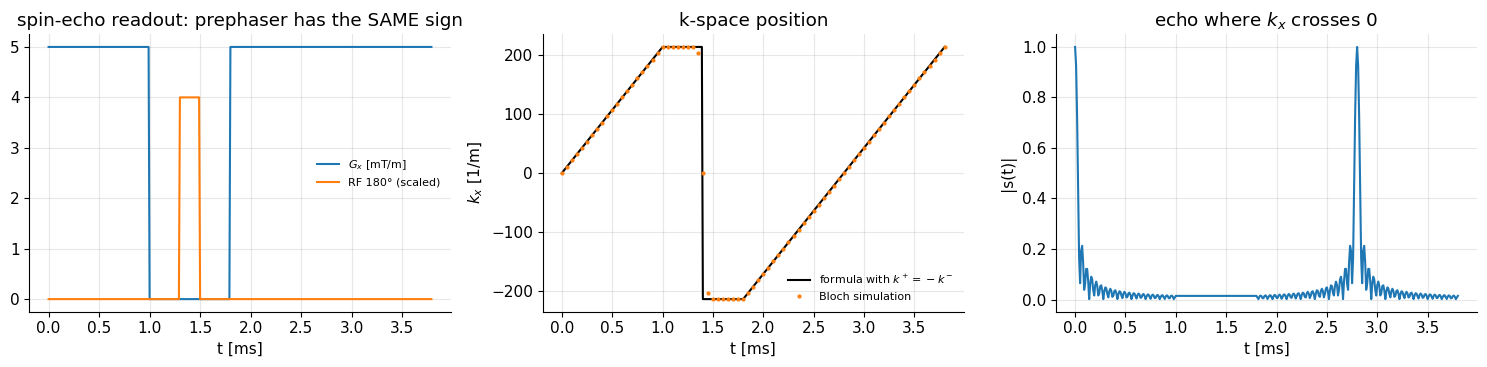

In [9]:
dt = 10e-6                                     # [s]
x = np.linspace(-0.05, 0.05, 201)              # 0.5 mm spacing (fine enough for |k| < 1000 1/m)
r = np.stack([x, 0 * x, 0 * x], axis=-1)
G0 = 5e-3                                      # [T/m]
n_pre, n_gap, n_rf, n_read = 100, 30, 20, 200  # 1 ms prephaser, 0.3 ms gap, 0.2 ms RF, 2 ms readout
Gx = np.concatenate([G0 * np.ones(n_pre), np.zeros(n_gap + n_rf + n_gap), G0 * np.ones(n_read)])
b1 = np.zeros(len(Gx), complex)
b1_amp = mt.b1_for_flip(np.pi, n_rf * dt)      # hard 180 deg pulse along x [T]
b1[n_pre + n_gap: n_pre + n_gap + n_rf] = b1_amp
G = np.zeros((len(Gx), 3)); G[:, 0] = Gx
t, M = mt.bloch_simulate(B1=b1, G=G, r=r, dt=dt, M_init=(1.0, 0.0, 0.0))
Mxy = M[:, :, 0] + 1j * M[:, :, 1]

# local wavenumber from the simulation: phase(x) = -2 pi k x  ->  k = -d(phase)/dx / (2 pi)
dphi = np.angle(np.sum(Mxy[:, 1:] * np.conj(Mxy[:, :-1]), axis=1))
k_sim = -dphi / (2 * np.pi * (x[1] - x[0]))

# k-space formula: running integral, reflected k -> -k at the 180 pulse center
k_formula = mt.GAMMA_BAR * np.concatenate([[0], np.cumsum(Gx)]) * dt
i180 = n_pre + n_gap + n_rf // 2
k_formula[i180:] = -k_formula[i180] + (k_formula[i180:] - k_formula[i180])

fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
ax[0].plot(t[:-1] * 1e3, Gx * 1e3, label="$G_x$ [mT/m]")
ax[0].plot(t[:-1] * 1e3, np.abs(b1) / b1_amp * 4, label="RF 180° (scaled)")
ax[0].set(xlabel="t [ms]", title="spin-echo readout: prephaser has the SAME sign"); ax[0].legend(fontsize=8)
ax[1].plot(t * 1e3, k_formula, "k", label="formula with $k^+=-k^-$")
ax[1].plot(t[::5] * 1e3, k_sim[::5], "C1.", ms=4, label="Bloch simulation")
ax[1].set(xlabel="t [ms]", ylabel="$k_x$ [1/m]", title="k-space position"); ax[1].legend(fontsize=8)
ax[2].plot(t * 1e3, np.abs(Mxy.mean(axis=1)))
ax[2].set(xlabel="t [ms]", ylabel="|s(t)|", title="echo where $k_x$ crosses 0")
plt.tight_layout(); plt.show()

Interpretation: during the prephaser $k_x$ climbs to $+213$ m⁻¹; the 180° pulse (orange trace in the left panel) flips it to $-213$ m⁻¹; the readout gradient then carries it back through zero, producing the echo 1 ms into the readout. The Bloch simulation (orange dots) follows the formula exactly — the k-space picture is just a compact description of the phase of the magnetization. (In a real spin echo the 180° pulse simultaneously refocuses off-resonance phase, with the spin echo and the gradient echo designed to coincide.)

## 6. Example k-space trajectories

The majority of MRI uses **Cartesian** trajectories, in which parallel lines of k-space are covered to sample a 2D (or 3D) grid; this is the trajectory of frequency-encoding plus phase-encoding (FT imaging). K-space trajectories with other patterns, such as **radial** lines, **spirals**, rastered lines (**echo-planar**, EPI), or rotating blades (PROPELLER/BLADE), can also be used. The main requirement is that a sufficient region of k-space is measured, densely enough. The specific requirements for that region depend on the desired resolution and field of view ([FOV and Resolution](../pass2_deep_dive/G1_FOV_and_Resolution.ipynb)) and are also affected by any accelerated imaging method being used ([Accelerated Imaging Methods](../pass2_deep_dive/H3_Accelerated_Imaging_Methods.ipynb)).

Python port of the original trajectory plots (normalized units, $k$ in cycles/pixel, $N = 8$):

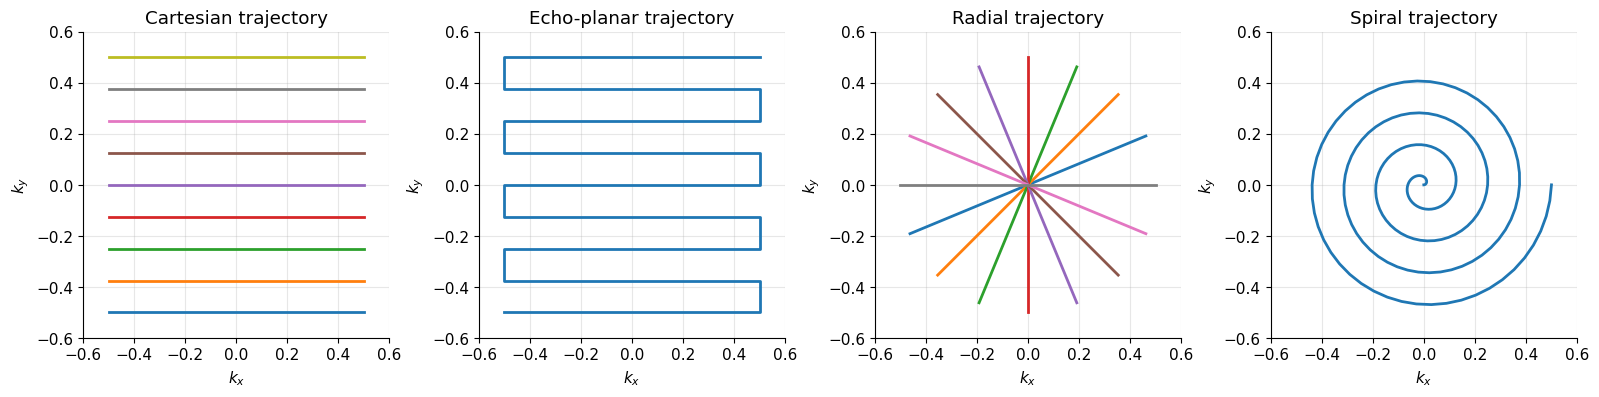

In [10]:
N = 8
k = np.linspace(-N / 2, N / 2, N + 1) / N
ky_c, kx_c = np.meshgrid(k, k)

fig, axs = plt.subplots(1, 4, figsize=(16, 4.2))
# Cartesian: one line per phase-encoding step
axs[0].plot(kx_c, ky_c, lw=2); axs[0].set_title("Cartesian trajectory")
# Echo-planar: raster through all lines in one go (every other line reversed)
kx_ep = ky_c.copy(); kx_ep[1::2, :] = kx_ep[1::2, ::-1]
ky_ep = kx_c.copy()
axs[1].plot(kx_ep.flatten(), ky_ep.flatten(), lw=2); axs[1].set_title("Echo-planar trajectory")
# Radial: N spokes through the center, angles spread over 180 degrees
theta = 2 * np.pi * np.arange(1, N + 1) / (2 * N)
k_radial = np.outer(k, np.exp(1j * theta))
for i in range(N):
    axs[2].plot(k_radial[:, i].real, k_radial[:, i].imag, lw=2)
axs[2].set_title("Radial trajectory")
# Spiral: Archimedean spiral with N/2 turns
n = np.linspace(0, 1, 201)
Nturns = N / 2
k_spiral = 0.5 * n * np.exp(1j * 2 * np.pi * Nturns * n)
axs[3].plot(k_spiral.real, k_spiral.imag, lw=2); axs[3].set_title("Spiral trajectory")
for a in axs:
    a.set(xlim=(-.6, .6), ylim=(-.6, .6), xlabel="$k_x$", ylabel="$k_y$"); a.set_aspect("equal")
plt.tight_layout(); plt.show()

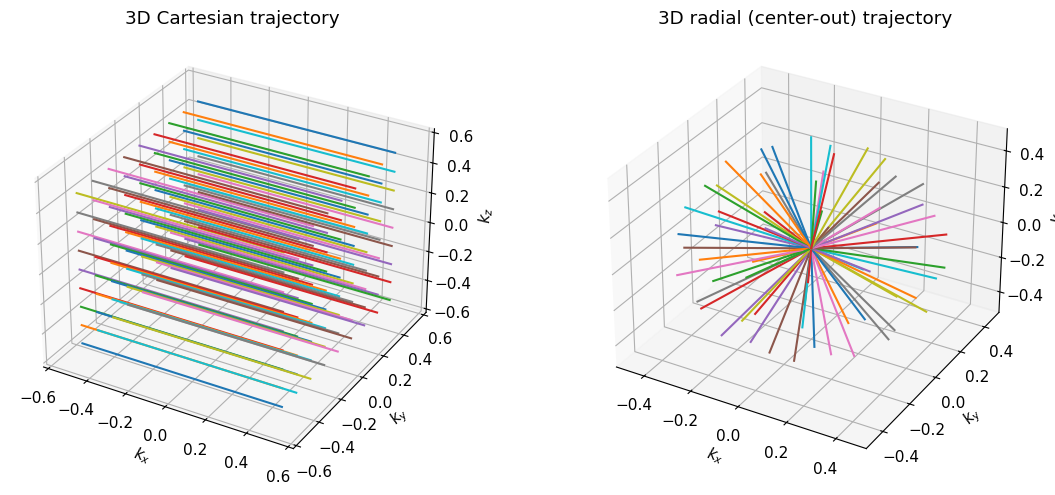

In [11]:
# 3D trajectories (port of the original)
k = np.linspace(-N / 2, N / 2, N + 1) / N
kx3, ky3, kz3 = np.meshgrid(k, k, k)
fig = plt.figure(figsize=(12, 5))
ax = fig.add_subplot(121, projection="3d")
for i in range(kx3.shape[0]):
    for j in range(kx3.shape[1]):
        ax.plot(kz3[i, j, :], ky3[i, j, :], kx3[i, j, :], lw=1.5)   # readout lines along one axis
ax.set(xlim=(-.6, .6), ylim=(-.6, .6), zlim=(-.6, .6), xlabel="$k_x$", ylabel="$k_y$", zlabel="$k_z$",
       title="3D Cartesian trajectory")
# 3D radial: N^2 spokes from the center with directions spread over the sphere (spiral-phyllotaxis-like)
N_radial = N**2
nn = np.arange(1, N_radial + 1)
kz_r = (2 * nn - N_radial - 1) / N_radial
phi = np.sqrt(N_radial * np.pi) * np.arcsin(kz_r)
kx_r = np.cos(phi) * np.sqrt(1 - kz_r**2) / 2
ky_r = np.sin(phi) * np.sqrt(1 - kz_r**2) / 2
kz_r = kz_r / 2
ax = fig.add_subplot(122, projection="3d")
for i in range(N_radial):
    ax.plot([0, kx_r[i]], [0, ky_r[i]], [0, kz_r[i]], lw=1.5)
ax.set(xlim=(-.5, .5), ylim=(-.5, .5), zlim=(-.5, .5), xlabel="$k_x$", ylabel="$k_y$", zlabel="$k_z$",
       title="3D radial (center-out) trajectory")
plt.tight_layout(); plt.show()

Interpretation: Cartesian and EPI sample the same grid but EPI does it in a single excitation (one long zig-zag); radial and spiral trajectories are non-Cartesian (samples do not lie on a grid), which requires a different reconstruction (gridding, [Image Reconstruction](../pass2_deep_dive/F3_Image_Reconstruction.ipynb)). The 3D radial spokes here start at the center ("center-out"), as used in ultrashort-TE (UTE) imaging.

These movies from the original illustrate the phase accumulation during non-Cartesian trajectories:

![Radial trajectory: M_xy arrows, gradients and k-space trajectory for each spoke](../images/radial_encoding-full-Mxy.gif)

![Spiral trajectory: M_xy arrows, gradients and k-space trajectory](../images/spiral_encoding-full-Mxy.gif)

### Gradients for EPI and spiral trajectories (and why hardware matters)

Using $\vec G = \frac{1}{\bar\gamma}\frac{d\vec k}{dt}$ we can turn a desired trajectory into gradient waveforms and check them against the hardware limits (here 40 mT/m and 150 T/m/s).

**EPI:** each line is read with an alternating readout gradient, and short **blips** on $G_y$ (area $\Delta k_y/\bar\gamma$) step from line to line. We build an idealized EPI train (instantaneous ramps for simplicity) for 64×64, FOV 240 mm, $BW_{read}$ = 250 kHz:

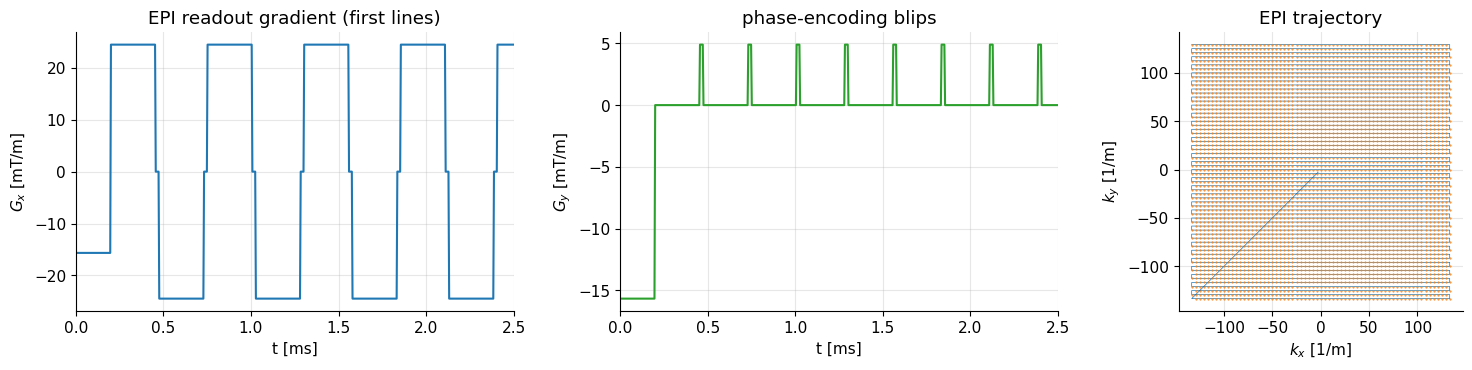

readout amplitude 24.5 mT/m, echo spacing 0.276 ms, whole image in 17.8 ms (one excitation!)
blip amplitude 4.9 mT/m;  with real ramps at 150 T/m/s, reversing ±24.5 mT/m takes 326 us per line


In [12]:
FOV, Ne = 0.24, 64
BW_epi = 250e3
dtd = 1 / BW_epi                                  # dwell time [s]
G_ro = BW_epi / (mt.GAMMA_BAR * FOV)              # readout amplitude [T/m]
n_blip = 5                                        # blip duration in samples
Gx_list, Gy_list, adc_list = [], [], []
# prephaser to the corner (-kmax, -kmax), 50 samples long
A_corner = -(Ne / 2) / FOV / mt.GAMMA_BAR
Gx_list += [np.full(50, A_corner / (50 * dtd))]; Gy_list += [np.full(50, A_corner / (50 * dtd))]
adc_list += [np.zeros(50, bool)]
for line in range(Ne):
    sign = 1 if line % 2 == 0 else -1
    Gx_list += [np.full(Ne, sign * G_ro)]; Gy_list += [np.zeros(Ne)]; adc_list += [np.ones(Ne, bool)]
    if line < Ne - 1:                              # blip to the next line
        Gx_list += [np.zeros(n_blip)]; Gy_list += [np.full(n_blip, (1 / FOV) / mt.GAMMA_BAR / (n_blip * dtd))]
        adc_list += [np.zeros(n_blip, bool)]
Gx_e, Gy_e, adc_e = map(np.concatenate, (Gx_list, Gy_list, adc_list))
te = np.arange(len(Gx_e)) * dtd
kx_e, ky_e = k_from_gradients(Gx_e, dtd), k_from_gradients(Gy_e, dtd)

fig, ax = plt.subplots(1, 3, figsize=(15, 3.8), gridspec_kw={"width_ratios": [1.4, 1.4, 1]})
ax[0].plot(te * 1e3, Gx_e * 1e3); ax[0].set(xlim=(0, 2.5), xlabel="t [ms]", ylabel="$G_x$ [mT/m]",
                                            title="EPI readout gradient (first lines)")
ax[1].plot(te * 1e3, Gy_e * 1e3, "C2"); ax[1].set(xlim=(0, 2.5), xlabel="t [ms]", ylabel="$G_y$ [mT/m]",
                                                  title="phase-encoding blips")
ax[2].plot(kx_e, ky_e, lw=0.5); ax[2].plot(kx_e[adc_e], ky_e[adc_e], ".", ms=1)
ax[2].set(xlabel="$k_x$ [1/m]", ylabel="$k_y$ [1/m]", title="EPI trajectory"); ax[2].set_aspect("equal")
plt.tight_layout(); plt.show()
esp = (Ne + n_blip) * dtd
print(f"readout amplitude {G_ro*1e3:.1f} mT/m, echo spacing {esp*1e3:.3f} ms, "
      f"whole image in {len(te)*dtd*1e3:.1f} ms (one excitation!)")
print(f"blip amplitude {Gy_e.max()*1e3:.1f} mT/m;  with real ramps at 150 T/m/s, reversing ±{G_ro*1e3:.1f} mT/m "
      f"takes {2*G_ro/150*1e6:.0f} us per line")

Interpretation: a full 64×64 image is acquired in ~18 ms after a single excitation (compare 64 × TR for Cartesian). The price: high bandwidth and amplitude, rapidly alternating gradients (loud, limited by slew rate and nerve stimulation), and — because k-space is traversed slowly in the blip direction (one line per echo spacing ≈ 0.28 ms) — strong sensitivity to off-resonance, causing distortion along $y$ ([Fast Imaging Pulse Sequences](../pass2_deep_dive/H2_Fast_Imaging_Pulse_Sequences.ipynb), [Artifacts](../pass2_deep_dive/I2_Artifacts.ipynb)).

**Spiral:** an Archimedean spiral $k(t) = k_{max}\,\frac{t}{T}\,e^{i2\pi N_{turns}t/T}$ (with $k=k_x+ik_y$) needs $N_{turns} = k_{max}\cdot FOV = N/2$ turns so that successive turns are $\Delta k = 1/FOV$ apart. Splitting it into $N_{int}$ rotated **interleaves** (one per excitation) relaxes the hardware demands. Let us compute $G$ and the slew rate for 64×64, FOV 24 cm, 8 ms readout:

N_int = 1: max |G| =   78.7 mT/m, max slew =    1970 T/m/s
N_int = 8: max |G| =    9.8 mT/m, max slew =      31 T/m/s


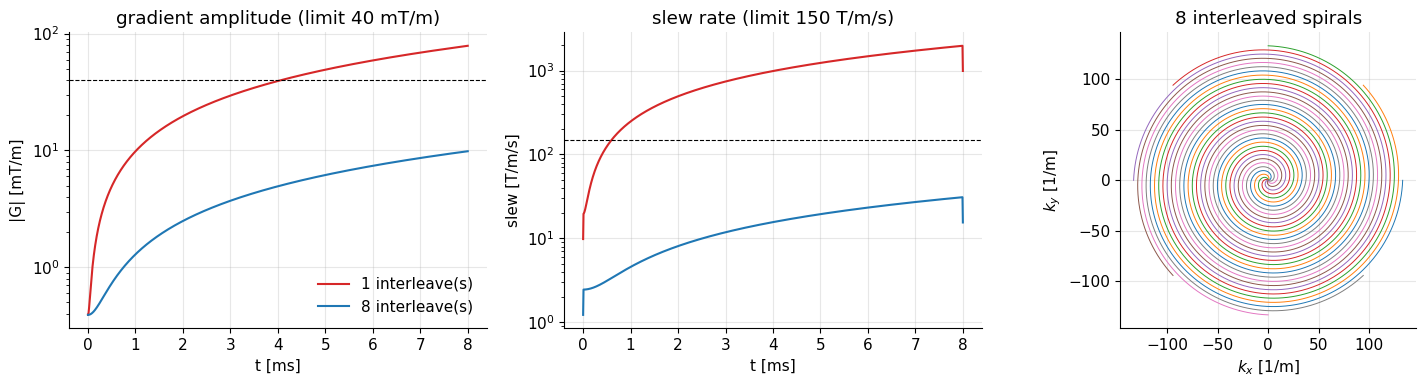

In [13]:
kmax = (Ne / 2) / FOV                              # [1/m]
T_sp = 8e-3                                        # readout duration [s]
dts = 4e-6
ts = np.arange(0, T_sp, dts)
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for N_int, col in [(1, "C3"), (8, "C0")]:
    turns = (Ne / 2) / N_int                       # turns per interleave
    ksp = kmax * (ts / T_sp) * np.exp(1j * 2 * np.pi * turns * ts / T_sp)
    Gsp = np.gradient(ksp, dts) / mt.GAMMA_BAR     # complex: G_x + i G_y  [T/m]
    SRsp = np.gradient(Gsp, dts)                   # [T/m/s]
    ax[0].plot(ts * 1e3, np.abs(Gsp) * 1e3, col, label=f"{N_int} interleave(s)")
    ax[1].plot(ts * 1e3, np.abs(SRsp), col, label=f"{N_int} interleave(s)")
    print(f"N_int = {N_int}: max |G| = {np.abs(Gsp).max()*1e3:6.1f} mT/m, max slew = {np.abs(SRsp).max():7.0f} T/m/s")
    if N_int == 8:
        for il in range(N_int):
            kk = ksp * np.exp(1j * 2 * np.pi * il / N_int)
            ax[2].plot(kk.real, kk.imag, lw=0.7)
ax[0].axhline(40, color="k", ls="--", lw=0.8); ax[0].set(xlabel="t [ms]", ylabel="|G| [mT/m]", yscale="log",
                                                         title="gradient amplitude (limit 40 mT/m)")
ax[1].axhline(150, color="k", ls="--", lw=0.8); ax[1].set(xlabel="t [ms]", ylabel="slew [T/m/s]", yscale="log",
                                                          title="slew rate (limit 150 T/m/s)")
ax[0].legend(); ax[2].set(xlabel="$k_x$ [1/m]", ylabel="$k_y$ [1/m]", title="8 interleaved spirals"); ax[2].set_aspect("equal")
plt.tight_layout(); plt.show()

Interpretation: a single-shot spiral at this resolution, played in 8 ms with constant angular speed, would need roughly twice the available gradient amplitude and more than ten times the available slew rate — physically impossible. With 8 interleaves both demands drop below the limits. Real spiral designs additionally use variable angular velocity (slew-limited near the center, amplitude-limited at the edge) to get the most out of the hardware ([Gradient System Engineering](../pass2_deep_dive/B4_Gradient_System_Engineering.ipynb)).

### Sampling density

Non-Cartesian trajectories do not sample k-space uniformly. For radial, all spokes pass through the center, so the density of samples falls like $1/|k|$:

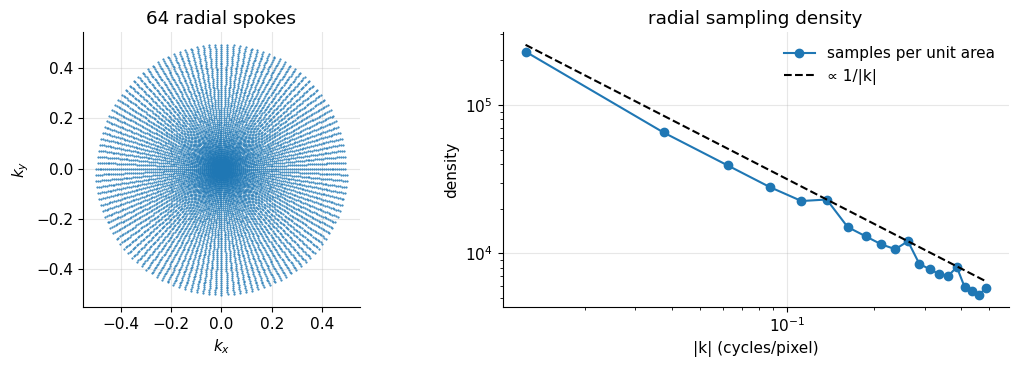

In [14]:
n_spokes, n_samp = 64, 128
kr_line = (np.arange(n_samp) - n_samp // 2) / n_samp          # cycles/pixel along a spoke
ang = np.pi * np.arange(n_spokes) / n_spokes
krad = (kr_line[None, :] * np.exp(1j * ang[:, None])).ravel()
bins = np.linspace(0, 0.5, 21)
cnt, _ = np.histogram(np.abs(krad), bins=bins)
area_ring = np.pi * (bins[1:]**2 - bins[:-1]**2)
centers = 0.5 * (bins[1:] + bins[:-1])
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].plot(krad.real, krad.imag, ".", ms=1); ax[0].set_aspect("equal")
ax[0].set(title=f"{n_spokes} radial spokes", xlabel="$k_x$", ylabel="$k_y$")
ax[1].loglog(centers, cnt / area_ring, "o-", label="samples per unit area")
ax[1].loglog(centers, (cnt / area_ring)[5] * centers[5] / centers, "k--", label="∝ 1/|k|")
ax[1].set(xlabel="|k| (cycles/pixel)", ylabel="density", title="radial sampling density"); ax[1].legend()
plt.tight_layout(); plt.show()

Interpretation: the center is heavily oversampled and the periphery undersampled. Before a Fourier reconstruction, each sample must therefore be weighted by a **density compensation** factor (≈ $|k|$ for radial), and samples must be interpolated onto a grid (**gridding**) — see [Image Reconstruction](../pass2_deep_dive/F3_Image_Reconstruction.ipynb) and [Advanced Image Reconstruction](../pass2_deep_dive/J5_Advanced_Image_Reconstruction.ipynb). The oversampled center is also why radial imaging is robust to motion (each spoke re-measures the image contrast).

### Trajectory comparison

| Trajectory | Samples per excitation | Strengths | Weaknesses / artifacts | Hardware demand |
|---|---|---|---|---|
| Cartesian (2DFT) | 1 line | robust, simple FFT recon, artifacts well understood | slow ($N_{PE}$ TRs), motion ghosts along PE | low |
| EPI | all lines (single-shot) or several | very fast (~20–100 ms per image): fMRI, diffusion | off-resonance distortion, $T_2^*$ blur, N/2 ghost from odd/even line mismatch | very high slew, loud, PNS |
| Radial | 1 spoke | motion-robust, oversampled center, graceful undersampling (streaks) | needs gridding; sensitive to gradient delays | moderate |
| Spiral | 1 interleave (or whole image) | very efficient coverage, short TE possible | off-resonance blur, needs gridding and accurate trajectory | high |
| PROPELLER/BLADE | 1 blade (short Cartesian strip) | motion correction from repeated center | longer scan | moderate |

> **🔧 Engineering reality:** for non-Cartesian and EPI imaging, the *actual* trajectory deviates from the nominal one due to gradient delays (a few µs) and eddy currents. Scanners calibrate these, and some reconstructions use a measured trajectory (from field probes or calibration scans). A delay of 5 µs at $\bar\gamma G = 266$ kHz/m (6.26 mT/m) shifts k by ≈ 1.3 m⁻¹ — a third of $\Delta k$ — enough to cause visible artifacts in radial imaging.

### Try it yourself (interactive)

Pick a phase-encoding step of the realistic GRE sequence and see its gradients and trajectory (widget output is not stored when the notebook is executed headless; the static figures above show representative steps).

In [15]:
try:
    from ipywidgets import interact, IntSlider
    def show_pe(n_pe=129):
        t, Gx, Gy, adc = gre_waveforms(n_pe)
        d = t[1] - t[0]
        kx, ky = k_from_gradients(Gx, d), k_from_gradients(Gy, d)
        fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
        ax[0].plot(t * 1e3, Gx * 1e3, label="$G_x$"); ax[0].plot(t * 1e3, Gy * 1e3, label="$G_y$")
        ax[0].set(xlabel="t [ms]", ylabel="mT/m"); ax[0].legend()
        ax[1].plot(kx, ky); ax[1].plot(kx[adc], ky[adc], "r.", ms=2)
        ax[1].set(xlim=(-600, 600), ylim=(-600, 600), xlabel="$k_x$ [1/m]", ylabel="$k_y$ [1/m]"); ax[1].set_aspect("equal")
        plt.show()
    interact(show_pe, n_pe=IntSlider(129, 1, 256))
except ImportError:
    print("ipywidgets not available")

interactive(children=(IntSlider(value=129, description='n_pe', max=256, min=1), Output()), _dom_classes=('widg…

## Key takeaways

* Gradients imprint a position-dependent phase: $M_{xy}(\vec r,t)=m(\vec r)\,e^{-i2\pi\vec k(t)\cdot\vec r}$ with $\vec k(t)=\bar\gamma\int_0^t\vec G\,d\tau$ [1/m]; only the running gradient **area** matters.
* The signal is the Fourier transform of the object at the current k-space location: $s(t)=M(\vec k(t))$. MRI measures spatial frequencies; an inverse FT gives the image.
* One k-space sample = overlap of the object with one stripe pattern (wavelength $1/|\vec k|$). The **center** carries signal and contrast, the **edges** carry fine detail and edges.
* Trajectory from gradients: integrate ($\Delta\vec k=\bar\gamma\vec A$ per lobe). Gradients from trajectory: differentiate ($\vec G=\frac{1}{\bar\gamma}d\vec k/dt$); slew rate = k-space acceleration.
* A negative prephaser moves $k_x$ to $-k_{max}$ so the readout crosses $k_x=0$ (the gradient echo) at TE; rewinders return to $k=0$; spoilers move far out; a 180° pulse maps $\vec k\to-\vec k$.
* Cartesian, EPI, radial and spiral trajectories trade speed against robustness and hardware demand; non-Cartesian sampling needs density compensation and gridding.

## Check your understanding

1. A gradient of $G_x = -8$ mT/m is applied for 0.5 ms, then $G_x=+4$ mT/m. When does the gradient echo occur, and what is $k_x$ at the end of the negative lobe?

<details><summary>Answer</summary>

At the end of the negative lobe $k_x = \bar\gamma A = 42.58\times10^6\cdot(-8\times10^{-3})\cdot0.5\times10^{-3}\approx -170$ m⁻¹. The positive lobe needs the same area, $4\ \text{mT/m}\times t = 4\ \text{mT/m·ms}$ → $t = 1$ ms. The echo occurs 1 ms after the start of the positive lobe (1.5 ms after the start of the first lobe).

</details>

2. What does the single k-space sample at $\vec k = (0, 50)$ m⁻¹ measure, physically?

<details><summary>Answer</summary>

The overlap (integral) of the object with a complex stripe pattern $e^{-i2\pi\cdot 50\,y}$: stripes parallel to $x$ that repeat every 2 cm along $y$ (12 cycles across a 24 cm FOV). It tells how much of the object's structure varies with that period along $y$.

</details>

3. You reconstruct an image using only the central 10% of k-space (in each direction). What do you expect to see? And using only the outer part?

<details><summary>Answer</summary>

Central part only: a blurry, low-resolution image with correct overall brightness and contrast (and some ringing at sharp edges because of the hard cutoff). Outer part only: an "edge map" with almost no overall brightness — fine detail and boundaries only.

</details>

4. In a spin-echo sequence, the readout prephaser is placed before the 180° pulse. Should it be positive or negative if the readout gradient is positive? Why?

<details><summary>Answer</summary>

Positive (same sign as the readout). It moves $k_x$ to $+k_{max}$; the 180° pulse reflects it to $-k_{max}$; the positive readout then sweeps from $-k_{max}$ through 0 to $+k_{max}$. A negative prephaser would end up at $+k_{max}$ after the 180° and the readout would move further away — no echo.

</details>

5. Why does a single-shot spiral or EPI readout put higher demands on the gradient system than a Cartesian readout of the same image?

<details><summary>Answer</summary>

It covers all of k-space in one readout of a few tens of ms instead of $N_{PE}$ separate readouts. Moving through k-space faster needs larger $|G|=|d\vec k/dt|/\bar\gamma$, and the constant changes of direction (zig-zag, circling) need large slew rates $|dG/dt|$. These are limited by amplifier voltage/current, heating and peripheral nerve stimulation.

</details>

---
*Adapted and extended from P. Larson, "Principles of MRI" (MIT License), chapter "K-space".
Changes: added the derivation of the phase factor from the Bloch equation, Bloch-simulation checks of gradient echoes and of the 180° k-space reflection, stripe-pattern and center/edge demonstrations on real data, a realistic SI-unit GRE trajectory with prephaser and rewinders, EPI/spiral gradient design with hardware limits, radial sampling density and a trajectory comparison table; ported all original code to a consistent style; fixed typos ("frequnecy", "which is differs", "use in creating", "We have now have") and clarified that a 180° pulse conjugates $M_{xy}$.*